# Model Terbaik Bernoulli Naive Bayes untuk Klasifikasi Domain Punycode

Notebook ini menyajikan proses lengkap **BernoulliNB** untuk identifikasi domain phishing menggunakan data nyata dan sintetis. Model hanya memakai hostname yang dinormalisasi; path, query, protokol, dan sumber dataset tidak menjadi fitur.

BernoulliNB dipilih karena memperoleh F1 cross-validation tertinggi pada perbandingan lima model Naive Bayes.

## Mengapa BernoulliNB Cocok?

Setiap character n-gram diperlakukan sebagai fitur hadir/tidak hadir. Pendekatan ini cocok untuk domain karena pola seperti `xn--`, potongan nama merek, kombinasi angka-huruf, dan fragmen label lebih penting dari berapa kali fragmen tersebut berulang.

Asumsi BernoulliNB adalah kemunculan setiap fitur bersifat independen setelah kelas diketahui. Asumsi tersebut tidak sepenuhnya benar, tetapi efektif sebagai model yang cepat, transparan, dan sesuai untuk fitur biner berdimensi tinggi.

## 1. Persiapan Lingkungan

In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
)

SEED = 42
N_REGULAR = 65_000
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5.5), "axes.titleweight": "bold"})
print("Lingkungan siap | Seed:", SEED)

Lingkungan siap | Seed: 42


**Ringkasan output:** pustaka berhasil dimuat dan seed ditetapkan agar pembagian data serta pencarian parameter dapat direproduksi.

## 2. Membentuk Dataset yang Sama

Komposisi yang digunakan adalah 65.000 Tranco, 65.000 PhishTank, 5.000 Punycode legitimate-source, dan 5.000 Punycode phishing-source. Konflik URL identik dengan label berbeda disaring dari kandidat Tranco.

In [2]:
BASE_DIR = Path.cwd()
required = ["tranco_6WNKX.csv", "verified_online.csv",
            "legitimate_punycode_5000.csv", "phishing_punycode_5000.csv"]
assert all((BASE_DIR / f).exists() for f in required), "Ada file dataset yang tidak ditemukan."

legit_puny_raw = pd.read_csv(BASE_DIR / required[2]).head(5_000)
phish_puny_raw = pd.read_csv(BASE_DIR / required[3]).head(5_000)
legit_puny = legit_puny_raw[["url", "label", "source_url"]].rename(
    columns={"source_url": "source_key"}).assign(data_type="synthetic", source_dataset="Punycode")
phish_puny = phish_puny_raw[["url", "label", "source_url"]].rename(
    columns={"source_url": "source_key"}).assign(data_type="synthetic", source_dataset="Punycode")

phishtank = pd.read_csv(BASE_DIR / required[1]).drop_duplicates("url").head(N_REGULAR)
phish_real = pd.DataFrame({
    "url": phishtank["url"].astype(str).str.strip(), "label": "phishing",
    "source_key": phishtank["url"].astype(str).str.strip(),
    "data_type": "real", "source_dataset": "PhishTank",
})

tranco = pd.read_csv(BASE_DIR / required[0], header=None, names=["rank", "domain"],
                     nrows=70_000).drop_duplicates("domain")
tranco = tranco[~("https://" + tranco["domain"].astype(str).str.strip()).isin(set(phish_real["url"]))]
tranco = tranco.head(N_REGULAR)
legit_real = pd.DataFrame({
    "url": "https://" + tranco["domain"].astype(str).str.strip(), "label": "legitimate",
    "source_key": tranco["domain"].astype(str).str.strip(),
    "data_type": "real", "source_dataset": "Tranco",
})

df = pd.concat([legit_real, phish_real, legit_puny, phish_puny], ignore_index=True)
assert len(df) == 140_000 and df["url"].nunique() == 140_000
display(pd.crosstab([df["source_dataset"], df["data_type"]], df["label"], margins=True))
print(f"Total: {len(df):,} | Duplikat: {df['url'].duplicated().sum()}")

,label,legitimate,phishing,All
source_dataset,data_type,,,
PhishTank,real,0,65000,65000
Punycode,synthetic,5000,5000,10000
Tranco,real,65000,0,65000
All,,70000,70000,140000


Total: 140,000 | Duplikat: 0


**Ringkasan output:** dataset berisi 140.000 URL unik dan kelas seimbang, masing-masing 70.000 legitimate dan phishing. Komposisi yang identik dengan eksperimen GaussianNB membuat perbandingan model tetap adil.

## 3. Normalisasi dan Ekstraksi Domain

Hostname dikonversi ke lowercase, trailing dot dan prefiks `www.` dihapus. Model hanya menerima string domain hasil normalisasi.

In [3]:
def normalized_domain(url):
    parsed = urlsplit(url if "://" in url else "https://" + url)
    host = (parsed.hostname or "").lower().rstrip(".")
    return host[4:] if host.startswith("www.") else host

df["domain"] = df["url"].map(normalized_domain)
df["contains_punycode"] = df["domain"].str.contains("xn--").astype(int)
assert (df["domain"] != "").all()

domain_audit = pd.Series({
    "domain_kosong": (df["domain"] == "").sum(),
    "domain_unik": df["domain"].nunique(),
    "domain_dengan_xn--": df["contains_punycode"].sum(),
})
display(domain_audit.to_frame("jumlah"))
display(df[["url", "domain", "label", "data_type"]].head(8))

,jumlah
domain_kosong,0
domain_unik,106412
domain_dengan_xn--,10127


,url,domain,label,data_type
0,https://google.com,google.com,legitimate,real
1,https://gtld-servers.net,gtld-servers.net,legitimate,real
2,https://cloudflare.com,cloudflare.com,legitimate,real
3,https://gstatic.com,gstatic.com,legitimate,real
4,https://facebook.com,facebook.com,legitimate,real
5,https://microsoft.com,microsoft.com,legitimate,real
6,https://googleapis.com,googleapis.com,legitimate,real
7,https://youtube.com,youtube.com,legitimate,real


**Ringkasan output:** semua URL berhasil diekstrak menjadi domain. Jumlah domain unik dapat lebih kecil dari jumlah URL karena PhishTank dapat memuat path berbeda pada hostname yang sama. Kondisi ini ditangani melalui group-aware split berdasarkan sumber URL.

## 4. Membagi Dataset 80:20

URL asli dan transformasi Punycode yang berhubungan ditempatkan pada partisi sama. Pembagian dilakukan per kelas agar proporsi legitimate dan phishing tetap seimbang.

In [4]:
y = df["label"].map({"legitimate": 0, "phishing": 1})
train_idx, test_idx = [], []
for cls in [0, 1]:
    idx = df.index[y == cls].to_numpy()
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
    local_train, local_test = next(splitter.split(idx, groups=df.loc[idx, "source_key"]))
    train_idx.extend(idx[local_train]); test_idx.extend(idx[local_test])

train_idx, test_idx = np.array(train_idx), np.array(test_idx)
domain_train, domain_test = df.loc[train_idx, "domain"], df.loc[test_idx, "domain"]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
assert set(df.loc[train_idx, "source_key"]).isdisjoint(set(df.loc[test_idx, "source_key"]))

split_table = pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()})
split_table.index = split_table.index.map({0: "legitimate", 1: "phishing"})
display(split_table)
print(f"Train: {len(train_idx):,} | Test: {len(test_idx):,} | Kebocoran grup: 0")

,train,test
label,,
legitimate,56009,13991
phishing,56033,13967


Train: 112,042 | Test: 27,958 | Kebocoran grup: 0


**Ringkasan output:** sekitar 80% data digunakan untuk pelatihan dan 20% untuk pengujian. Tidak terdapat pasangan sumber yang melintasi train dan test sehingga risiko kebocoran transformasi berkurang.

## 5. TF-IDF Character N-gram

N-gram 2–5 karakter menangkap potongan lokal domain. Vectorizer hanya belajar vocabulary dari data train. Batas 80.000 fitur menjaga kebutuhan memori tetap terkendali.

In [5]:
vectorizer = TfidfVectorizer(
    analyzer="char", ngram_range=(2, 5), min_df=2,
    max_features=80_000, sublinear_tf=True, lowercase=False,
)
X_train = vectorizer.fit_transform(domain_train)
X_test = vectorizer.transform(domain_test)

print("Bentuk train:", X_train.shape)
print("Bentuk test :", X_test.shape)
print("Non-zero TF-IDF train:", f"{X_train.nnz:,}")
display(pd.Series(vectorizer.get_feature_names_out()).sample(20, random_state=SEED).to_frame("contoh_ngram"))

Bentuk train: (112042, 80000)
Bentuk test : (27958, 80000)
Non-zero TF-IDF train: 5,431,314


,contoh_ngram
47044,ltura
44295,ktopl
74783,v-ap
70975,to-m
46645,loq
8215,2u
65509,sa.e
62715,rienc
39859,igk
58834,penwe


**Ringkasan output:** setiap domain telah berubah menjadi vektor sparse dengan maksimal 80.000 fitur. Contoh n-gram menunjukkan bahwa model menerima potongan karakter, bukan label atau nama sumber dataset.

## 6. Pelatihan BernoulliNB dan Pemilihan Alpha

BernoulliNB diuji pada beberapa nilai `alpha` menggunakan GroupKFold. F1 phishing dipakai sebagai kriteria karena menyeimbangkan precision dan recall.

In [6]:
cv = GroupKFold(n_splits=3)
train_groups = df.loc[train_idx, "source_key"]
search = GridSearchCV(
    BernoulliNB(binarize=0.0),
    {"alpha": [0.01, 0.05, 0.1, 0.5, 1.0]},
    scoring="f1", cv=cv, n_jobs=1, return_train_score=True,
)
search.fit(X_train, y_train, groups=train_groups)
model = search.best_estimator_

tuning = pd.DataFrame(search.cv_results_)[
    ["param_alpha", "mean_train_score", "mean_test_score", "std_test_score"]
].sort_values("mean_test_score", ascending=False)
display(tuning.style.format({
    "param_alpha": "{:.2g}", "mean_train_score": "{:.4f}",
    "mean_test_score": "{:.4f}", "std_test_score": "{:.4f}",
}))
print("Alpha terbaik:", search.best_params_["alpha"])
print(f"F1 cross-validation terbaik: {search.best_score_:.4f}")

,param_alpha,mean_train_score,mean_test_score,std_test_score
0,0.01,0.9415,0.9343,0.0011
1,0.05,0.9380,0.9318,0.0016
2,0.1,0.9360,0.9302,0.0012
3,0.5,0.9291,0.9248,0.0022
4,1,0.9244,0.9208,0.0014


Alpha terbaik: 0.01
F1 cross-validation terbaik: 0.9343


**Ringkasan output:** `alpha=0,01` menghasilkan F1 cross-validation terbaik, yaitu **0,9343**. Nilai alpha kecil memberikan smoothing ringan sehingga n-gram yang jarang tetap informatif tanpa menghasilkan probabilitas nol.

## 7. Prediksi dan Perbandingan Metrik

In [7]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

def metric_row(subset, truth, pred, prob):
    return {
        "subset": subset, "n": len(truth),
        "accuracy": accuracy_score(truth, pred),
        "precision": precision_score(truth, pred, zero_division=0),
        "recall": recall_score(truth, pred, zero_division=0),
        "f1": f1_score(truth, pred, zero_division=0),
        "roc_auc": roc_auc_score(truth, prob),
        "pr_auc": average_precision_score(truth, prob),
    }

test_types = df.loc[test_idx, "data_type"].to_numpy()
rows = [metric_row("Keseluruhan", y_test, y_pred, y_prob)]
for kind, title in [("real", "Data nyata"), ("synthetic", "Data sintetis")]:
    mask = test_types == kind
    rows.append(metric_row(title, y_test.to_numpy()[mask], y_pred[mask], y_prob[mask]))
metrics = pd.DataFrame(rows)
display(metrics.style.format({c: "{:.4f}" for c in metrics.columns[2:]}))
print(classification_report(y_test, y_pred, target_names=["legitimate", "phishing"], digits=4))

,subset,n,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Keseluruhan,27958,0.9353,0.9800,0.8886,0.9321,0.9702,0.9762
1,Data nyata,26000,0.9356,0.9800,0.8893,0.9325,0.9703,0.9763
2,Data sintetis,1958,0.9316,0.9804,0.8790,0.9269,0.9684,0.9752


              precision    recall  f1-score   support

  legitimate     0.8983    0.9819    0.9382     13991
    phishing     0.9800    0.8886    0.9321     13967

    accuracy                         0.9353     27958
   macro avg     0.9391    0.9353    0.9351     27958
weighted avg     0.9391    0.9353    0.9352     27958



**Ringkasan output:** BernoulliNB memperoleh accuracy **93,53%**, precision **98,00%**, recall **88,86%**, dan F1 **93,21%**. F1 data nyata **93,25%** dan sintetis **92,69%**, sehingga performanya relatif konsisten pada kedua jenis data.

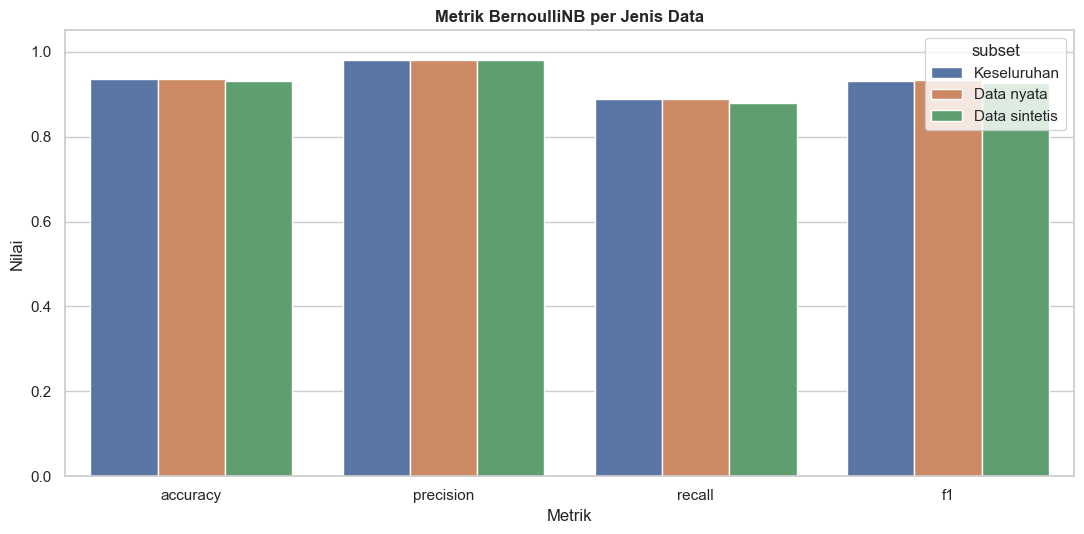

In [8]:
metric_long = metrics.melt(id_vars=["subset", "n"],
                            value_vars=["accuracy", "precision", "recall", "f1"])
plt.figure(figsize=(11, 5.5))
sns.barplot(data=metric_long, x="variable", y="value", hue="subset")
plt.title("Metrik BernoulliNB per Jenis Data")
plt.xlabel("Metrik"); plt.ylabel("Nilai"); plt.ylim(0, 1.05)
plt.tight_layout(); plt.show()

**Ringkasan output:** grafik memudahkan pemeriksaan trade-off. Model dengan accuracy tinggi belum tentu terbaik jika recall phishing rendah.

## 8. Evaluasi Model Terbaik

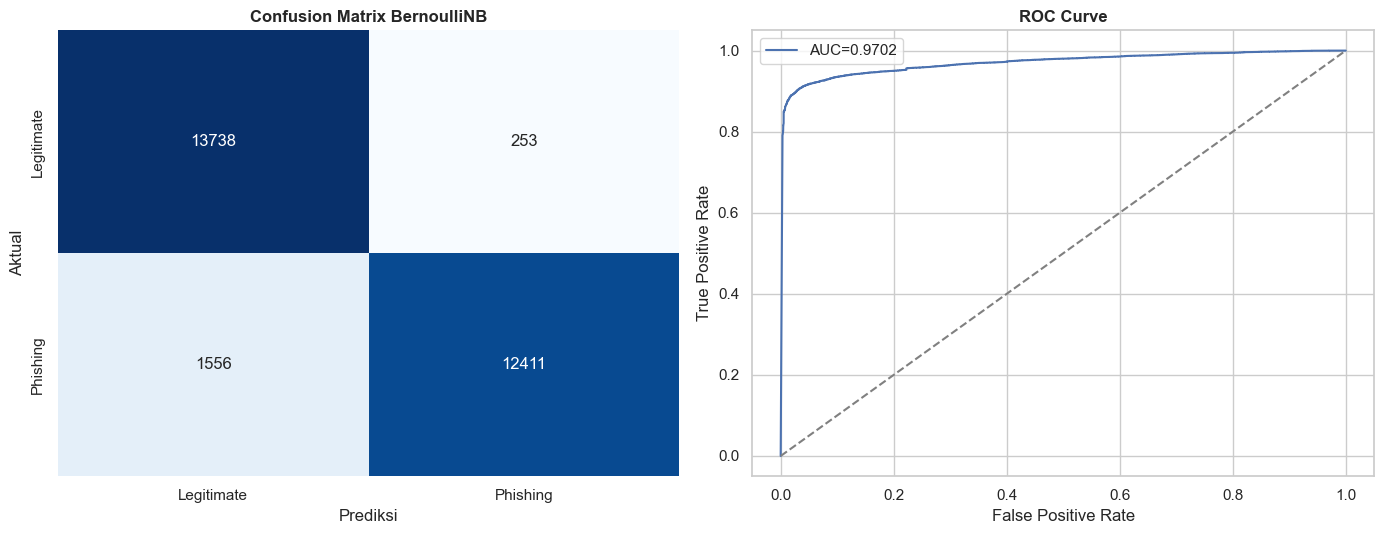

TN=13,738 | FP=253 | FN=1,556 | TP=12,411


In [9]:
cm = confusion_matrix(y_test, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Legitimate", "Phishing"], yticklabels=["Legitimate", "Phishing"], ax=axes[0])
axes[0].set(title="Confusion Matrix BernoulliNB", xlabel="Prediksi", ylabel="Aktual")
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, label=f"AUC={roc_auc_score(y_test, y_prob):.4f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set(title="ROC Curve", xlabel="False Positive Rate", ylabel="True Positive Rate")
axes[1].legend(); plt.tight_layout(); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}")

**Ringkasan output:** BernoulliNB menghasilkan **253 false positive** dan **1.556 false negative**. Jumlah false negative turun tajam dibandingkan GaussianNB, tetapi masih perlu diperhatikan karena domain phishing tersebut lolos sebagai legitimate. ROC-AUC BernoulliNB mencapai **97,02%**.

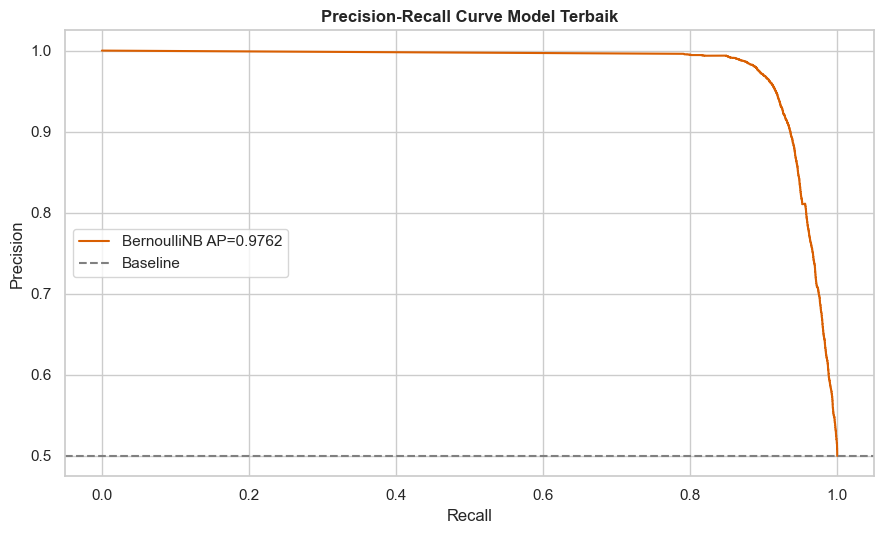

In [10]:
pr_precision, pr_recall, thresholds = precision_recall_curve(y_test, y_prob)
plt.figure(figsize=(9, 5.5))
plt.plot(pr_recall, pr_precision, color="#d95f02",
         label=f"BernoulliNB AP={average_precision_score(y_test, y_prob):.4f}")
plt.axhline(y_test.mean(), linestyle="--", color="gray", label="Baseline")
plt.title("Precision-Recall Curve Model Terbaik")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend(); plt.tight_layout(); plt.show()

**Ringkasan output:** precision-recall curve menunjukkan perubahan precision ketika recall dinaikkan. Kurva ini dapat digunakan dalam penelitian lanjutan untuk memilih threshold yang menekan false negative tanpa menghasilkan terlalu banyak false positive.

## 9. N-gram Paling Informatif

Selisih log-probability menunjukkan n-gram yang relatif lebih kuat untuk setiap kelas. Nilai ini merupakan asosiasi statistik, bukan bukti sebab-akibat.

In [11]:
feature_names = vectorizer.get_feature_names_out()
score = model.feature_log_prob_[1] - model.feature_log_prob_[0]
top_n = 20
phish_idx = np.argsort(score)[-top_n:][::-1]
legit_idx = np.argsort(score)[:top_n]
important = pd.DataFrame({
    "n_gram_phishing": feature_names[phish_idx],
    "skor_phishing": score[phish_idx],
    "n_gram_legitimate": feature_names[legit_idx],
    "skor_legitimate": -score[legit_idx],
})
display(important.round(4))

,n_gram_phishing,skor_phishing,n_gram_legitimate,skor_legitimate
0,ocs.g,13.0164,sdns-,10.5743
1,.wix,12.8722,wsdn,10.5718
2,.wixs,12.8712,wsdns,10.5718
3,.wee,12.8160,awsdn,10.4198
4,.weeb,12.8160,casi,10.0306
5,rco.d,12.8154,asino,10.0083
6,qrco.,12.8154,casin,10.0083
7,q-r.t,12.5371,u.edu,9.9238
8,q-r.,12.5371,ov.i,9.6096
9,-r.to,12.5371,gov.i,9.5893


**Ringkasan output:** daftar n-gram menjelaskan pola karakter yang mendorong prediksi. Pola perlu diperiksa agar model tidak hanya menghafal domain populer atau artefak generator sintetis.

## 10. Analisis Kesalahan

In [12]:
errors = df.loc[test_idx, ["url", "domain", "label", "data_type"]].copy()
errors["prediksi"] = np.where(y_pred == 1, "phishing", "legitimate")
errors["probabilitas_phishing"] = y_prob
false_positive = errors[(errors["label"] == "legitimate") & (errors["prediksi"] == "phishing")]
false_negative = errors[(errors["label"] == "phishing") & (errors["prediksi"] == "legitimate")]
print("False positive:", len(false_positive)); display(false_positive.sort_values("probabilitas_phishing", ascending=False).head(10))
print("False negative:", len(false_negative)); display(false_negative.sort_values("probabilitas_phishing").head(10))

False positive: 253


,url,domain,label,data_type,prediksi,probabilitas_phishing
252,https://linktr.ee,linktr.ee,legitimate,real,phishing,1.0
764,https://allegro.pl,allegro.pl,legitimate,real,phishing,1.0
4720,https://campaign-archive.com,campaign-archive.com,legitimate,real,phishing,1.0
4178,https://google.co.ve,google.co.ve,legitimate,real,phishing,1.0
7661,https://firebasedatabase.app,firebasedatabase.app,legitimate,real,phishing,1.0
8164,https://mail-archive.com,mail-archive.com,legitimate,real,phishing,1.0
8484,https://allegro.hu,allegro.hu,legitimate,real,phishing,1.0
9201,https://servicewebly.com,servicewebly.com,legitimate,real,phishing,1.0
26108,https://xn--72cm8an6ed3b4dwe6bh.net,xn--72cm8an6ed3b4dwe6bh.net,legitimate,real,phishing,1.0
14047,https://sitezoogle.com,sitezoogle.com,legitimate,real,phishing,1.0


False negative: 1556


,url,domain,label,data_type,prediksi,probabilitas_phishing
83161,https://www.luxurylifestylebydiamondmariexxx.c...,luxurylifestylebydiamondmariexxx.com,phishing,real,legitimate,1.897429e-63
129933,http://syneoshealthlondon.co.uk.mcas.ms,syneoshealthlondon.co.uk.mcas.ms,phishing,real,legitimate,4.031271e-41
71920,https://evvietnam.com/tuhbjgp/ok/t7yh.html,evvietnam.com,phishing,real,legitimate,6.680514e-39
127110,http://trentino.edu.pe/,trentino.edu.pe,phishing,real,legitimate,3.917620e-37
79140,https://cdn.rex.contents.rakuten.co.jp/webcx-r...,cdn.rex.contents.rakuten.co.jp,phishing,real,legitimate,1.729066e-36
118652,https://dmfpaloaltonetworks.com/login/,dmfpaloaltonetworks.com,phishing,real,legitimate,2.611521e-35
118653,https://dmfpaloaltonetworks.com/login,dmfpaloaltonetworks.com,phishing,real,legitimate,2.611521e-35
129979,http://sun.eduzz.com/1571976,sun.eduzz.com,phishing,real,legitimate,2.640393e-35
92704,https://www.pows-of-japan.net/videos/1nodescri...,pows-of-japan.net,phishing,real,legitimate,4.216082e-35
126134,http://golflincs.co.uk.travelwatchdog.com/,golflincs.co.uk.travelwatchdog.com,phishing,real,legitimate,4.816312e-35


**Ringkasan output:** false negative masih lebih banyak daripada false positive. Penelitian lanjutan dapat mengatur threshold berdasarkan validation set untuk menaikkan recall, dengan konsekuensi lebih banyak domain legitimate ikut ditandai.

## Kesimpulan

BernoulliNB menjawab tujuan penelitian karena mengklasifikasikan domain legitimate/phishing menggunakan pola Punycode dan character n-gram pada gabungan data nyata serta sintetis. Performanya baik karena keberadaan fragmen karakter lebih sesuai untuk struktur domain daripada asumsi Gaussian pada fitur panjang dan entropi.

Hasil harus tetap dibatasi pada dataset eksperimen. Model tidak memeriksa reputasi, DNS, umur domain, sertifikat, atau isi halaman sehingga belum dapat menjadi satu-satunya mekanisme pemblokiran operasional.